# Chapter 2: Random Variables and Distribution Functions

The computational applications of this chapter of *Theory of Statistics*. The code is generated automatically from the book's `code/ch02/` files; see the book for the explanations and proofs.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ibrahimguney/statistical-theory/blob/main/notebooks/ch_02.ipynb)

$$
\newcommand{\R}{\mathbb{R}}\newcommand{\N}{\mathbb{N}}\newcommand{\E}{\mathbb{E}}
\newcommand{\P}{\mathbb{P}}\newcommand{\F}{\mathcal{F}}\newcommand{\I}{\mathbb{I}}
\newcommand{\Var}{\operatorname{Var}}\newcommand{\Cov}{\operatorname{Cov}}
\newcommand{\Corr}{\operatorname{Corr}}\newcommand{\MSE}{\operatorname{MSE}}
\newcommand{\Bias}{\operatorname{Bias}}\newcommand{\Normal}{\mathcal{N}}
\newcommand{\iid}{\overset{\text{i.i.d.}}{\sim}}\newcommand{\pto}{\xrightarrow{P}}
\newcommand{\dto}{\xrightarrow{d}}\newcommand{\X}{\mathbf{X}}\newcommand{\x}{\mathbf{x}}
$$

In [1]:
# Setup: numpy, scipy and matplotlib are preinstalled on Colab. Locally:
#   pip install -r code/requirements.txt
# Figure files (PDF) saved by the code are written to the _figures/ folder; the figures are
# also shown inside the notebook.
import os
os.makedirs("_figures", exist_ok=True)
os.chdir("_figures")
%matplotlib inline

## Empirical CDF and the Kolmogorov–Smirnov Distance

*Source file:* `code/ch02/c02_1_ecdf_ks_distance.py`

In [2]:
import numpy as np
from scipy.stats import norm

rng = np.random.default_rng(42)
x_grid = np.linspace(-3.5, 3.5, 1000)
f_theo = norm.cdf(x_grid)

for n in [20, 100, 1000, 10000]:
    samples = rng.normal(0.0, 1.0, size=n)
    ecdf = np.array([np.mean(samples <= x) for x in x_grid])
    ks_dist = np.max(np.abs(ecdf - f_theo))
    print(f"n = {n:5d} | KS distance: {ks_dist:.4f}")

n =    20 | KS distance: 0.1290
n =   100 | KS distance: 0.1215
n =  1000 | KS distance: 0.0291
n = 10000 | KS distance: 0.0087


## Empirical CDF and the Kolmogorov–Smirnov Distance (continued)

Note that the distance shrinks at a rate of roughly $1/\sqrt{n}$. The supremum computed over a grid is a lower approximation to the true $D_n$; the exact value can be computed in $O(n\log n)$ time from the sorted sample using $D_n=\max_i\max\{i/n-F(X_{(i)}),\,F(X_{(i)})-(i-1)/n\}$. The code below uses this exact formula, compares it with the DKW bound and plots the ECDF.

*Source file:* `code/ch02/c02_2_exact_ks_dkw_ecdf_plot.py`

n= 100 | P(D_n > 0.05) MC = 0.9544 | DKW bound = 1.0000 | E[sqrt(n) D_n] = 0.851


n= 400 | P(D_n > 0.05) MC = 0.2600 | DKW bound = 0.2707 | E[sqrt(n) D_n] = 0.861


n=1000 | P(D_n > 0.05) MC = 0.0131 | DKW bound = 0.0135 | E[sqrt(n) D_n] = 0.863


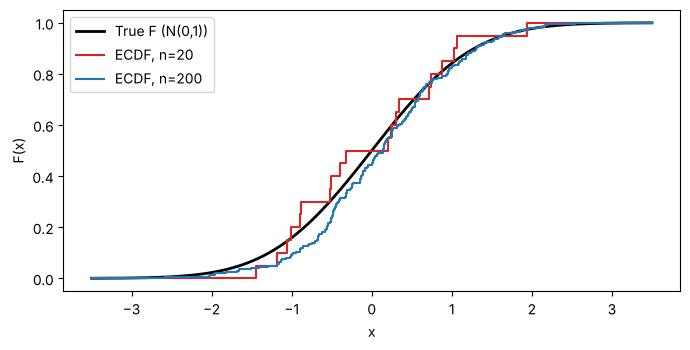

In [3]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
def ks_exact(x, cdf):
    x = np.sort(x); n = len(x); F = cdf(x); i = np.arange(1, n + 1)
    return max(np.max(i / n - F), np.max(F - (i - 1) / n))

eps, R = 0.05, 20_000
for n in [100, 400, 1000]:
    D = np.array([ks_exact(rng.normal(size=n), norm.cdf) for _ in range(R)])
    print(f"n={n:4d} | P(D_n > {eps}) MC = {np.mean(D > eps):.4f} | DKW bound = {min(1, 2*np.exp(-2*n*eps**2)):.4f}"
          f" | E[sqrt(n) D_n] = {np.sqrt(n)*D.mean():.3f}")

fig, ax = plt.subplots(figsize=(7, 3.6))
xg = np.linspace(-3.5, 3.5, 500)
ax.plot(xg, norm.cdf(xg), "k-", lw=2, label="True F (N(0,1))")
for n, c in [(20, "tab:red"), (200, "tab:blue")]:
    s = np.sort(rng.normal(size=n))
    ax.step(np.r_[-3.5, s, 3.5], np.r_[0, np.arange(1, n + 1) / n, 1], where="post", color=c, label=f"ECDF, n={n}")
ax.set_xlabel("x"); ax.set_ylabel("F(x)"); ax.legend(); fig.tight_layout()
fig.savefig("ecdf.pdf")

## Inverse Transform and the Probability Integral Transform

*Source file:* `code/ch02/c02_3_inverse_transform_pit.py`

In [4]:
import numpy as np
from scipy import stats

rng = np.random.default_rng(42)
U = rng.uniform(size=200_000)
lam = 2.0
X_exp = -np.log(1 - U) / lam                 # Exp(2)
X_cau = np.tan(np.pi * (U - 0.5))            # standard Cauchy
X_poi = np.searchsorted(stats.poisson.cdf(np.arange(60), 3.0), U)  # Poisson(3)

print(f"Exponential: mean={X_exp.mean():.4f} (theory {1/lam}), KS p-value={stats.kstest(X_exp, 'expon', args=(0, 1/lam)).pvalue:.3f}")
print(f"Cauchy     : median={np.median(X_cau):.4f} (theory 0), KS p-value={stats.kstest(X_cau, 'cauchy').pvalue:.3f}")
print(f"Poisson    : mean={X_poi.mean():.4f}, variance={X_poi.var():.4f} (theory 3, 3)")

# Probability integral transform: F(X) ~ U(0,1) (for continuous F)
Z = rng.gamma(3.0, 2.0, size=200_000)      # Gamma(3, rate 1/2); numpy takes scale = 1/rate
V = stats.gamma.cdf(Z, a=3.0, scale=2.0)
print(f"PIT: mean of F(X)={V.mean():.4f} (1/2), variance={V.var():.4f} (1/12={1/12:.4f})")

Exponential: mean=0.5002 (theory 0.5), KS p-value=0.964
Cauchy     : median=0.0004 (theory 0), KS p-value=0.964
Poisson    : mean=2.9998, variance=2.9995 (theory 3, 3)
PIT: mean of F(X)=0.4998 (1/2), variance=0.0833 (1/12=0.0833)
